**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/14_marginal_likelihood_and_model_comparison.ipynb)** | **📖 [Conceptual](../conceptual/14_marginal_likelihood_and_model_comparison.ipynb)** | **🔵 [R](../r/14_marginal_likelihood_and_model_comparison.ipynb)** | **⬅️ [Prev: Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** | **➡️ [Next: Ch 15: Dynamic Memory & Decay (γ)](15_calibrating_bayesian_decay_and_memory.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 14 of 22*

---

# Chapter 14: Likelihood vs. Marginal Likelihood, Occam's Razor & Model Comparison
### *Interactive Laboratory: Evidence Integration, Bayes Factors & Cross-Validation*

---

## 🧭 The Learning Progression
1. **Part 1: Likelihood vs. Marginal Likelihood**: Calculate point likelihood
versus Bayesian evidence for coin tosses by exact analytical integration.
2. **Part 2: The Probability Budget & Occam Factor**: Visualize how model
complexity dilutes prior predictive density across dataset space.
3. **Part 3: Bayes Factors & Lindley's Paradox**: Observe how diffuse priors
inadvertently penalize hypotheses in Bayesian hypothesis testing.
4. **Part 4: Structural Attribution vs. Out-of-Sample Prediction**: Fit
polynomial models (Degrees 1, 2, 3, 7) and contrast Marginal Likelihood with
Leave-One-Out Cross-Validation (LOO-CV).
5. **Part 5: 3-Tier Scaffolding Exercises**: Test your understanding with
hands-on computational problems from guided calculations to production code.


---

## Part 1: What Is Marginal Likelihood, and How Does It Differ from Likelihood?

In parameter estimation, we evaluate the **point likelihood** $P(\mathcal{D}
\mid \theta, \mathcal{M})$: the probability of the data given a single, fixed
coordinate $\theta$. Maximizing this function over $\theta$ always rewards
flexibility, leading to severe overfitting.

In Bayesian model comparison, we evaluate the **Marginal Likelihood** (or
**Bayesian Evidence**) $P(\mathcal{D} \mid \mathcal{M})$, which integrates the
likelihood across all possible parameter values weighted by the prior:

$$P(\mathcal{D} \mid \mathcal{M}) = \int_{\Theta} P(\mathcal{D} \mid \theta, \mathcal{M}) P(\theta \mid \mathcal{M}) \, d\theta$$

Because this is a definite integral across the parameter manifold $\Theta$, the
parameter vector $\theta$ disappears entirely. The resulting scalar represents
the average predictive performance of the model architecture itself.

### Worked Example: Fair Coin vs. Unknown Bias ($n=10, k=7$)
* **Model $\mathcal{M}_0$ (Fair Coin)**: Fixed parameter $p = 0.5$.
$$P(\mathcal{D} \mid \mathcal{M}_0) = \binom{10}{7} (0.5)^7 (0.5)^3 =
\frac{120}{1024} \approx 0.117188$$
* **Model $\mathcal{M}_1$ (Biased Coin)**: Prior $p \sim \text{Beta}(1, 1) =
  \text{Uniform}(0, 1)$.
$$P(\mathcal{D} \mid \mathcal{M}_1) = \int_0^1 \binom{10}{7} p^7 (1 - p)^3 \cdot
1 \, dp = \frac{1}{11} \approx 0.090909$$
* Notice that while the MLE $\hat{p} = 0.7$ gives peak likelihood $\approx
  0.2668$,
the *marginal likelihood* is only $0.0909$, giving $BF_{01} \approx 1.289$ in
favor of the simple fair coin!


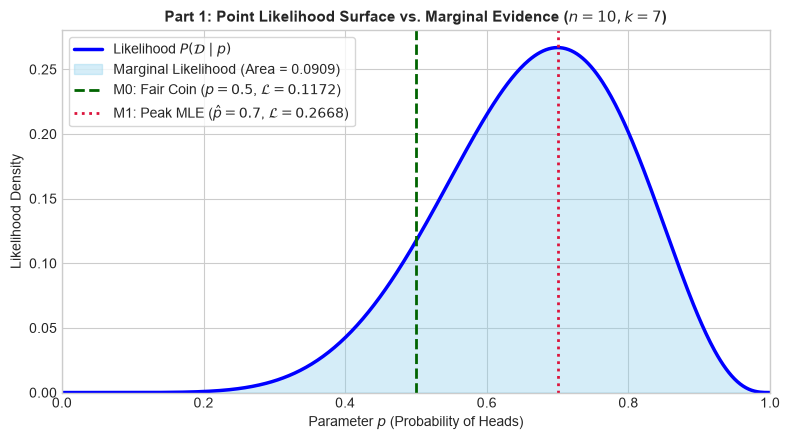

Model M0 (Fair Coin, p=0.5):        P(D | M0) = 0.117187
Model M1 (MLE at p=0.7):            P(D | p=0.7) = 0.266828
Model M1 (Marginal Evidence):       P(D | M1) = 0.090909
Bayes Factor BF_01: 1.289x in favor of Fair Coin!


In [1]:
# Part 1: Point Likelihood vs. Marginal Likelihood in Python
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.special as special

# 1. Experimental Setup: n = 10 tosses, k = 7 heads
n, k = 10, 7
p_grid = np.linspace(0, 1, 500)
likelihood_grid = stats.binom.pmf(k, n, p_grid)

# 2. Model Calculations
# M0: Fair coin (p = 0.5 exactly)
lik_m0 = stats.binom.pmf(k, n, 0.5)

# M1: Unknown bias with Beta(1, 1) prior
mle_p = k / n
lik_m1_mle = stats.binom.pmf(k, n, mle_p)
marg_lik_m1 = special.comb(n, k) * special.beta(k + 1, n - k + 1)
bf_01 = lik_m0 / marg_lik_m1

# 3. Visualization
style_name = ('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in
              plt.style.available else 'default')
plt.style.use(style_name)
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)

ax.plot(p_grid, likelihood_grid, 'b-', lw=2.5,
        label=r'Likelihood $P(\mathcal{D} \mid p)$')
ax.fill_between(p_grid, 0, likelihood_grid, color='skyblue', alpha=0.35,
                label=f'Marginal Likelihood (Area = {marg_lik_m1:.4f})')

# Mark Fair Coin and MLE
ax.axvline(0.5, color='darkgreen', linestyle='--', lw=2,
           label=rf'M0: Fair Coin ($p=0.5$, $\mathcal{{L}}={lik_m0:.4f}$)')
ax.axvline(mle_p, color='crimson', linestyle=':', lw=2,
           label=(f'M1: Peak MLE ($\hat{{p}}=0.7$, '
                  f'$\mathcal{{L}}={lik_m1_mle:.4f}$)'))

ax.set_title(
    r"Part 1: Point Likelihood Surface vs. Marginal Evidence ($n=10, k=7$)",
    fontsize=11, fontweight='bold')
ax.set_xlabel("Parameter $p$ (Probability of Heads)", fontsize=10)
ax.set_ylabel("Likelihood Density", fontsize=10)
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend(frameon=True, facecolor='white', loc='upper left')

plt.tight_layout()
plt.show()

print(f"Model M0 (Fair Coin, p=0.5):        P(D | M0) = {lik_m0:.6f}")
print(f"Model M1 (MLE at p=0.7):            P(D | p=0.7) = {lik_m1_mle:.6f}")
print(f"Model M1 (Marginal Evidence):       P(D | M1) = {marg_lik_m1:.6f}")
print(f"Bayes Factor BF_01: {bf_01:.3f}x in favor of Fair Coin!")

---

## Part 2: The Automatic Bayesian Occam's Razor (The Gambling Budget Analogy)

Why does Bayesian inference automatically penalize complexity without ad-hoc
penalty terms like AIC ($2k$) or BIC ($k \ln n$)?

### The Conservation of Probability
Every valid probabilistic model $\mathcal{M}$ defines a probability
distribution over all possible datasets $\mathcal{D}$:

$$\sum_{\mathcal{D}} P(\mathcal{D} \mid \mathcal{M}) = 1 \quad \text{or} \quad \int P(\mathcal{D} \mid \mathcal{M}) \, d\mathcal{D} = 1$$

Each model receives **exactly the same total probability budget: 1.0.**
* **Simple Model $\mathcal{M}_1$**: Spends its entire budget betting on a
compact domain of simple datasets. If the true data lands in this region,
the predictive density $P(\mathcal{D} \mid \mathcal{M}_1)$ is high.
* **Complex Model $\mathcal{M}_2$**: Spreads its budget across a vast universe
of possible datasets. Its density $P(\mathcal{D} \mid \mathcal{M}_2)$ is
diluted everywhere.

### The Occam Factor via Laplace Approximation
Around the posterior mode $\hat{\theta}$, the evidence decomposes as:

$$P(\mathcal{D} \mid \mathcal{M}) \approx P(\mathcal{D} \mid \hat{\theta}, \mathcal{M}) \times \underbrace{\frac{\Delta \theta_{\text{post}}}{\Delta \theta_{\text{prior}}}}_{\text{Occam Factor } < 1}$$

Where $\Delta \theta_{\text{post}}$ is the posterior uncertainty volume and
$\Delta \theta_{\text{prior}}$ is the prior parameter volume.


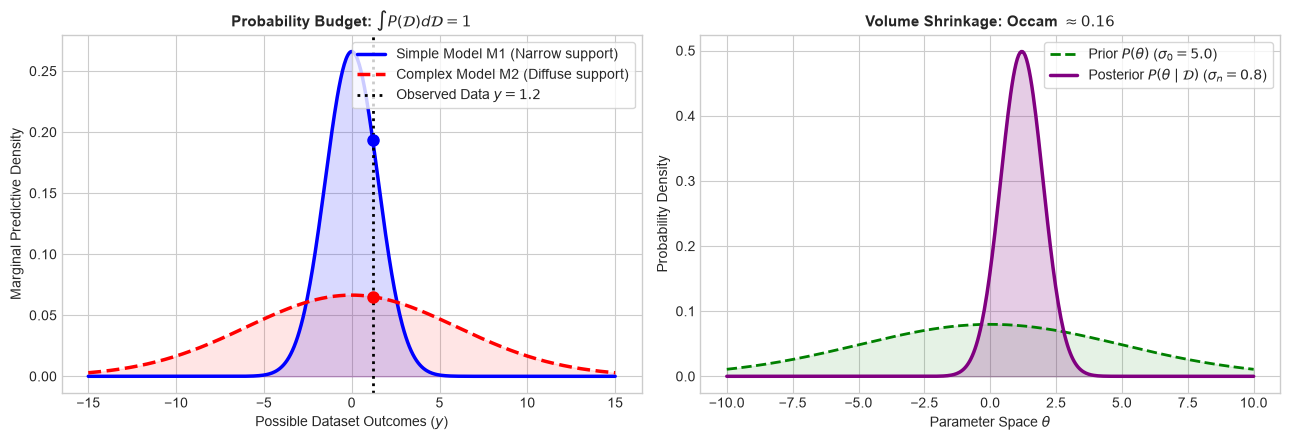

Density at y=1.2: M1 = 0.1931 vs. M2 = 0.0652
Bayes Factor BF_12: 2.96x in favor of Simple Model M1!


In [2]:
# Part 2: Visualizing the Probability Budget & The Occam Factor
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

y_domain = np.linspace(-15, 15, 600)
# Simple Model M1: Predicts narrow range of outcomes N(0, 1.5^2)
pdf_m1 = stats.norm.pdf(y_domain, loc=0, scale=1.5)
# Complex Model M2: Dilutes budget over wide range N(0, 6.0^2)
pdf_m2 = stats.norm.pdf(y_domain, loc=0, scale=6.0)

# Observed outcome
y_obs = 1.2
p_obs_m1 = stats.norm.pdf(y_obs, 0, 1.5)
p_obs_m2 = stats.norm.pdf(y_obs, 0, 6.0)
bf_12_budget = p_obs_m1 / p_obs_m2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)

# Subplot 1: The Probability Budget over Dataset Space
ax1.plot(y_domain, pdf_m1, 'b-', lw=2.5,
         label='Simple Model M1 (Narrow support)')
ax1.fill_between(y_domain, 0, pdf_m1, color='blue', alpha=0.15)
ax1.plot(y_domain, pdf_m2, 'r--', lw=2.5,
         label='Complex Model M2 (Diffuse support)')
ax1.fill_between(y_domain, 0, pdf_m2, color='red', alpha=0.10)

ax1.axvline(y_obs, color='black', linestyle=':', lw=2,
            label=f'Observed Data $y={y_obs}$')
ax1.plot([y_obs], [p_obs_m1], 'bo', markersize=8)
ax1.plot([y_obs], [p_obs_m2], 'ro', markersize=8)

ax1.set_title(
    r"Probability Budget: $\int P(\mathcal{D}) d\mathcal{D} = 1$",

    fontsize=11, fontweight='bold')
ax1.set_xlabel("Possible Dataset Outcomes ($y$)", fontsize=10)
ax1.set_ylabel("Marginal Predictive Density", fontsize=10)
ax1.legend(frameon=True, facecolor='white', loc='upper right')

# Subplot 2: Parameter Volume Shrinkage (The Occam Factor)
theta_grid = np.linspace(-10, 10, 400)
prior_pdf = stats.norm.pdf(theta_grid, 0, 5.0)     # Delta theta_prior = 10
post_pdf = stats.norm.pdf(theta_grid, 1.2, 0.8)     # Delta theta_post = 1.6

ax2.plot(theta_grid, prior_pdf, 'g--', lw=2,
         label=r'Prior $P(\theta)$ ($\sigma_0=5.0$)')
ax2.fill_between(theta_grid, 0, prior_pdf, color='green', alpha=0.1)
ax2.plot(theta_grid, post_pdf, 'purple', lw=2.5,
         label=r'Posterior $P(\theta \mid \mathcal{D})$ ($\sigma_n=0.8$)')
ax2.fill_between(theta_grid, 0, post_pdf, color='purple', alpha=0.2)

occam_factor = 0.8 / 5.0
ax2.set_title(f"Volume Shrinkage: Occam $\\approx {occam_factor:.2f}$",
              fontsize=11, fontweight='bold')
ax2.set_xlabel(r"Parameter Space $\theta$", fontsize=10)
ax2.set_ylabel("Probability Density", fontsize=10)
ax2.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.show()

print(f"Density at y={y_obs}: M1 = {p_obs_m1:.4f} vs. M2 = {p_obs_m2:.4f}")
print(f"Bayes Factor BF_12: {bf_12_budget:.2f}x in favor of Simple Model M1!")

---

## Part 3: Bayes Factors ($BF_{12}$) & Lindley's Paradox

The Bayes Factor updates prior model odds to posterior model odds:

$$\frac{P(\mathcal{M}_1 \mid \mathcal{D})}{P(\mathcal{M}_2 \mid \mathcal{D})} = \frac{P(\mathcal{M}_1)}{P(\mathcal{M}_2)} \times BF_{12}, \quad BF_{12} = \frac{P(\mathcal{D} \mid \mathcal{M}_1)}{P(\mathcal{D} \mid \mathcal{M}_2)}$$

### Harold Jeffreys' Scale of Evidence
* $BF_{12} \in [1, 3]$: Anecdotal / weak evidence
* $BF_{12} \in [3, 10]$: Substantial evidence
* $BF_{12} \in [10, 30]$: Strong evidence
* $BF_{12} > 100$: Decisive evidence

### Lindley's Paradox
Consider testing $H_0: \theta = 0$ against $H_1: \theta \sim \mathcal{N}(0,
\sigma_0^2)$
with $y_i \sim \mathcal{N}(\theta, \sigma^2)$.
When $z = \frac{\bar{y}}{\sigma / \sqrt{n}} = 2.58$, the frequentist $p$-value
is $p \approx 0.01$ (rejects $H_0$).

However, the analytical Bayes Factor in favor of $H_0$ is:

$$BF_{01} = \sqrt{1 + \frac{n \sigma_0^2}{\sigma^2}} \exp\left(-\frac{z^2}{2} \cdot \frac{\frac{n\sigma_0^2}{\sigma^2}}{1 + \frac{n\sigma_0^2}{\sigma^2}}\right)$$

As prior standard deviation $\sigma_0 \to \infty$, $BF_{01} \to \infty$!
**An arbitrarily diffuse prior guarantees that the null hypothesis will win,
even when the empirical evidence against the null is statistically
significant.**


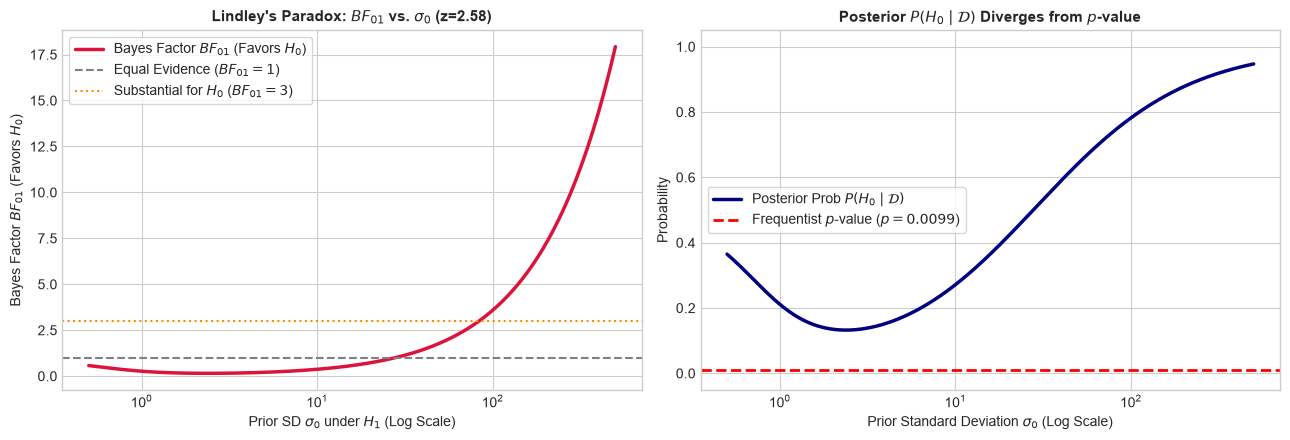

Frequentist p-value: 0.0099 (Rejects H0 at alpha=0.01)
BF_01 at sigma_0 = 1.0:   0.268 (Favors H1)
BF_01 at sigma_0 = 10.0:  0.375 (Weak evidence)
BF_01 at sigma_0 = 100.0: 3.559 (Favors H0!)


In [3]:
# Part 3: Simulating Lindley's Paradox in Python
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Fixed sample statistics: z = 2.58 (p = 0.00988 < 0.01)
z = 2.58
n = 100
sigma_obs = 10.0
se = sigma_obs / np.sqrt(n)  # se = 1.0, y_bar = 2.58
p_value = 2.0 * (1.0 - stats.norm.cdf(z))

# Sweep prior standard deviation sigma_0 from 0.5 to 500
sigma_0_values = np.logspace(np.log10(0.5), np.log10(500.0), 300)
tau_sq = (n * (sigma_0_values**2)) / (sigma_obs**2)  # n * sigma0^2 / sigma^2

# Bayes Factor BF_01 = P(D | H0) / P(D | H1)
term = tau_sq / (1.0 + tau_sq)
bf_01 = np.sqrt(1.0 + tau_sq) * np.exp(-0.5 * (z**2) * term)
# Equal prior odds P(H0) = P(H1) = 0.5
post_prob_h0 = bf_01 / (1.0 + bf_01)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)

# Subplot 1: Bayes Factor BF_01 vs. Prior Width sigma_0
ax1.plot(sigma_0_values, bf_01, 'crimson', lw=2.5,
         label=r'Bayes Factor $BF_{01}$ (Favors $H_0$)')
ax1.axhline(1.0, color='gray', linestyle='--',
            label='Equal Evidence ($BF_{01} = 1$)')
ax1.axhline(3.0, color='darkorange', linestyle=':',
            label=r'Substantial for $H_0$ ($BF_{01} = 3$)')

ax1.set_xscale('log')
ax1.set_title(
    rf"Lindley's Paradox: $BF_{{01}}$ vs. $\sigma_0$ (z={z:.2f})",

    fontsize=11, fontweight='bold')
ax1.set_xlabel(r"Prior SD $\sigma_0$ under $H_1$ (Log Scale)", fontsize=10)
ax1.set_ylabel(r"Bayes Factor $BF_{01}$ (Favors $H_0$)", fontsize=10)
ax1.legend(frameon=True, facecolor='white', loc='upper left')

# Subplot 2: Posterior Probability P(H0 | D) vs. Frequentist p-value
ax2.plot(sigma_0_values, post_prob_h0, 'navy', lw=2.5,
         label=r'Posterior Prob $P(H_0 \mid \mathcal{D})$')
ax2.axhline(p_value, color='red', linestyle='--', lw=2,
            label=f'Frequentist $p$-value ($p = {p_value:.4f}$)')

ax2.set_xscale('log')
ax2.set_title(r"Posterior $P(H_0 \mid \mathcal{D})$ Diverges from $p$-value",
              fontsize=11, fontweight='bold')
ax2.set_xlabel(r"Prior Standard Deviation $\sigma_0$ (Log Scale)", fontsize=10)
ax2.set_ylabel("Probability", fontsize=10)
ax2.set_ylim(-0.05, 1.05)
ax2.legend(frameon=True, facecolor='white', loc='center left')

plt.tight_layout()
plt.show()

print(f"Frequentist p-value: {p_value:.4f} (Rejects H0 at alpha=0.01)")
idx1 = np.argmin(np.abs(sigma_0_values - 1.0))
idx10 = np.argmin(np.abs(sigma_0_values - 10.0))
idx100 = np.argmin(np.abs(sigma_0_values - 100.0))
print(f"BF_01 at sigma_0 = 1.0:   {bf_01[idx1]:.3f} (Favors H1)")
print(f"BF_01 at sigma_0 = 10.0:  {bf_01[idx10]:.3f} (Weak evidence)")
print(f"BF_01 at sigma_0 = 100.0: {bf_01[idx100]:.3f} (Favors H0!)")

---

## Part 4: Bayes Factors vs. Out-of-Sample Cross-Validation (LOO-CV)

Two fundamentally different questions guide model comparison:
1. **Hypothesis Testing / Attribution ($\mathcal{M}$-Closed)**: Which model
reflects the true physical process? Evaluated via **Marginal Likelihood**
$\ln P(\mathcal{D} \mid \mathcal{M})$.
2. **Predictive Generalization ($\mathcal{M}$-Open)**: Which model best predicts
unseen future observations? Evaluated via **Leave-One-Out Cross-Validation**
(LOO-CV) and expected log pointwise predictive density (ELPD).

### Polynomial Test Suite (Degree 1, 2, 3, 7)
We simulate $N = 30$ observations from a quadratic ground truth:
$$y = 1.0 - 1.5x + 0.8x^2 + \epsilon, \quad \epsilon \sim \mathcal{N}(0, 0.5^2)$$

For Bayesian linear regression $\mathbf{y} \sim
\mathcal{N}(\mathbf{X}\boldsymbol{\beta}, \sigma^2 \mathbf{I})$
with conjugate prior $\boldsymbol{\beta} \sim \mathcal{N}(\mathbf{0}, \sigma_0^2
\mathbf{I})$,
the marginal likelihood is exact:

$$\ln P(\mathbf{y} \mid \mathbf{X}, \mathcal{M}) = -\frac{N}{2}\ln(2\pi) - \frac{N-p}{2}\ln(\sigma^2) - \frac{p}{2}\ln(\sigma_0^2) - \frac{1}{2}\ln|\boldsymbol{\Sigma}_n^{-1}| - \frac{1}{2}\text{SSE}_{\text{post}}$$

And the LOO-CV residual shortcut via leverage diagonal $h_{ii}$ is:
$$r_{i, -i} = \frac{y_i - \hat{y}_i}{1 - h_{ii}}$$


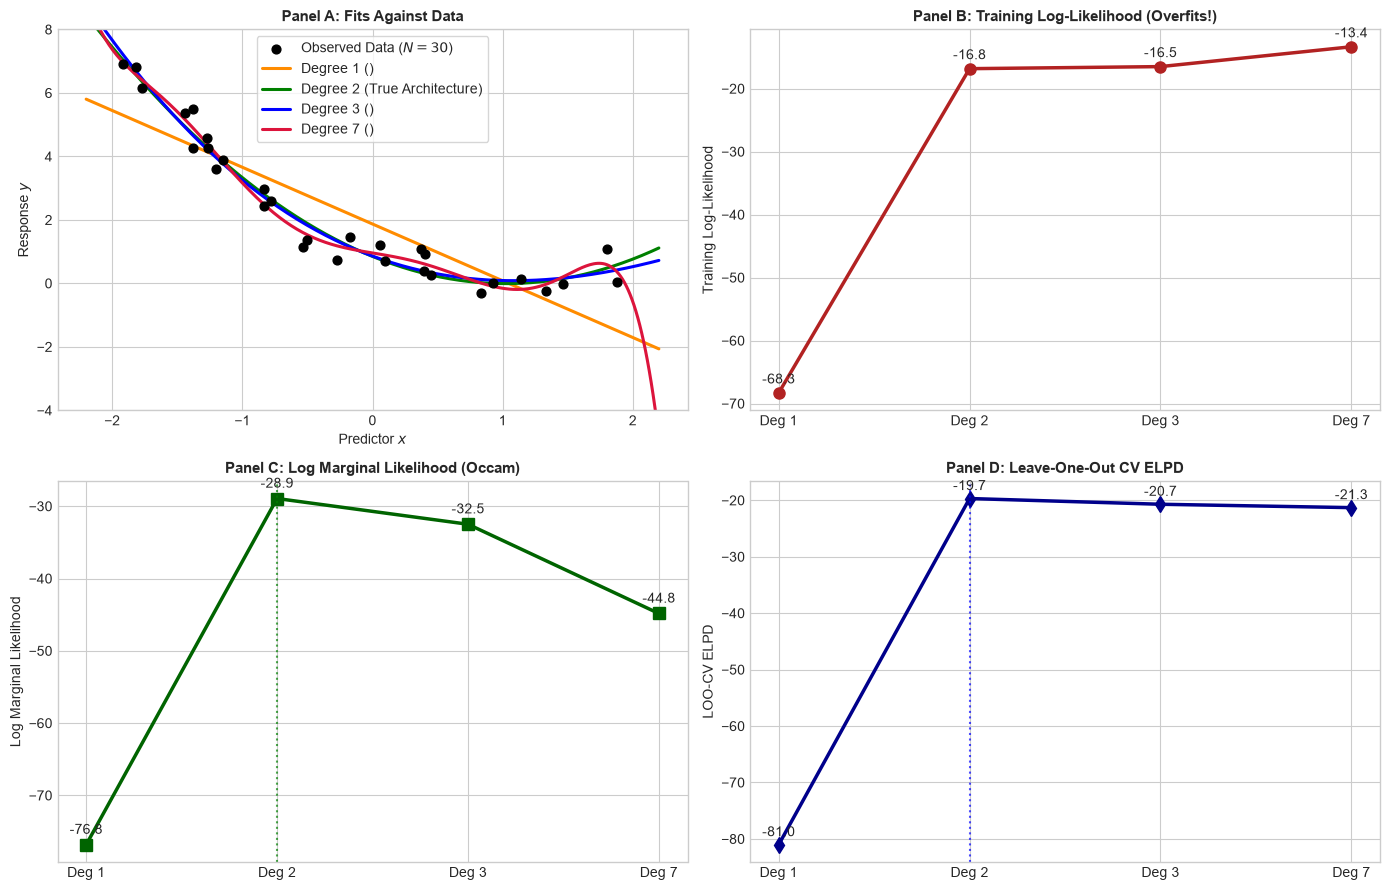

In [4]:
# Part 4: Polynomial Model Suite Simulation in Python
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
N = 30
x = np.random.uniform(-2, 2, N)
sigma_noise = 0.5
sigma0 = 2.0
# Ground truth: Degree 2
y = 1.0 - 1.5 * x + 0.8 * (x**2) + np.random.normal(0, sigma_noise, N)

degrees = [1, 2, 3, 7]
train_lls, marg_liks, loo_elpds = [], [], []

x_plot = np.linspace(-2.2, 2.2, 300)
fitted_curves = {}

for d in degrees:
    X = np.vander(x, d + 1, increasing=True)
    X_plot = np.vander(x_plot, d + 1, increasing=True)
    p = d + 1
    
    # Posterior precision and covariance
    XtX = X.T @ X
    Xty = X.T @ y
    Sigma_post_inv = np.eye(p) / (sigma0**2) + XtX / (sigma_noise**2)
    Sigma_post = np.linalg.inv(Sigma_post_inv)
    mu_post = Sigma_post @ (Xty / (sigma_noise**2))
    
    # 1. Training Log-Likelihood
    y_pred = X @ mu_post
    res = y - y_pred
    ll_train = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(res**2) / (sigma_noise**2))
    train_lls.append(ll_train)
    
    # 2. Exact Log Marginal Likelihood
    sign, logdet_inv = np.linalg.slogdet(Sigma_post_inv)
    quad = np.sum(res**2) / (sigma_noise**2) + (mu_post @ mu_post) / (sigma0**2)
    log_marg = (-0.5 * N * np.log(2 * np.pi)
                - 0.5 * (N - p) * np.log(sigma_noise**2)
                - 0.5 * p * np.log(sigma0**2)
                - 0.5 * logdet_inv
                - 0.5 * quad)
    marg_liks.append(log_marg)
    
    # 3. Leave-One-Out Cross-Validation (LOO-CV)
    H = X @ Sigma_post @ X.T / (sigma_noise**2)
    h_diag = np.diag(H)
    loo_errors = (y - y_pred) / (1.0 - h_diag)
    loo_elpd = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(loo_errors**2) / (sigma_noise**2))
    loo_elpds.append(loo_elpd)
    
    fitted_curves[d] = X_plot @ mu_post

# 4-Panel Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=100)

# Panel 1: Fitted Curves
axes[0, 0].scatter(x, y, color='black', s=40, zorder=5,
                    label='Observed Data ($N=30$)')
colors = {1: 'darkorange', 2: 'green', 3: 'blue', 7: 'crimson'}
for d in degrees:
    axes[0, 0].plot(x_plot, fitted_curves[d], color=colors[d], lw=2.2,
                    label=f'Degree {d} ({"" if d!=2 else "True Architecture"})')
axes[0, 0].set_ylim(-4, 8)
axes[0, 0].set_title("Panel A: Fits Against Data", fontsize=11,
                      fontweight='bold')
axes[0, 0].set_xlabel("Predictor $x$", fontsize=10)
axes[0, 0].set_ylabel("Response $y$", fontsize=10)
axes[0, 0].legend(frameon=True, facecolor='white', loc='upper center')

# Panel 2: In-Sample Training Log-Likelihood (Overfitting Trap)
deg_labels = [f"Deg {d}" for d in degrees]
axes[0, 1].plot(deg_labels, train_lls, 'o-', color='firebrick',
                 lw=2.5, markersize=8)
axes[0, 1].set_title("Panel B: Training Log-Likelihood (Overfits!)",
                      fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel("Training Log-Likelihood", fontsize=10)
for i, txt in enumerate(train_lls):
    axes[0, 1].annotate(f"{txt:.1f}",
                        (deg_labels[i], train_lls[i] + 1.5), ha='center')

# Panel 3: Log Marginal Likelihood (Occam's Razor)
axes[1, 0].plot(deg_labels, marg_liks, 's-', color='darkgreen',
                 lw=2.5, markersize=8)
axes[1, 0].axvline('Deg 2', color='green', linestyle=':', alpha=0.7)
axes[1, 0].set_title("Panel C: Log Marginal Likelihood (Occam)",
                      fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Log Marginal Likelihood", fontsize=10)
for i, txt in enumerate(marg_liks):
    axes[1, 0].annotate(f"{txt:.1f}",
                        (deg_labels[i], marg_liks[i] + 1.5), ha='center')

# Panel 4: Out-of-Sample LOO-CV ELPD
axes[1, 1].plot(deg_labels, loo_elpds, 'd-', color='darkblue',
                 lw=2.5, markersize=8)
axes[1, 1].axvline('Deg 2', color='blue', linestyle=':', alpha=0.7)
axes[1, 1].set_title("Panel D: Leave-One-Out CV ELPD",
                      fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel("LOO-CV ELPD", fontsize=10)
for i, txt in enumerate(loo_elpds):
    axes[1, 1].annotate(f"{txt:.1f}",
                        (deg_labels[i], loo_elpds[i] + 1.5), ha='center')

plt.tight_layout()
plt.show()

---

## Part 5: Check Your Understanding (3-Tier Scaffolding Exercises)

Sharpen your mathematical intuition and hands-on skills with three structured
computational challenges.

---

### 🟢 Tier 1 (Guided Calculation): Point Likelihood vs. Evidence for Coin Flips

**Scenario**: You flip an unknown physical coin $n = 10$ times and observe
$k = 6$ heads. You want to test whether the coin is fair or biased:
* **Model $\mathcal{M}_0$ (Fair Coin)**: $p = 0.5$ exactly (0 free parameters).
* **Model $\mathcal{M}_1$ (Unknown Bias)**: $p \sim \text{Beta}(1, 1) =
  \text{Uniform}(0, 1)$ (1 free parameter).

**Your Task**:
1. Calculate the point likelihood of $\mathcal{M}_0$ at $p = 0.5$.
2. Calculate the maximum likelihood of $\mathcal{M}_1$ at the MLE $\hat{p} =
   0.6$.
3. Calculate the true marginal likelihood of $\mathcal{M}_1$ by evaluating the
Beta integral: $P(\mathcal{D} \mid \mathcal{M}_1) = \frac{1}{n+1}$.
4. Compute the Bayes Factor $BF_{01} = \frac{P(\mathcal{D} \mid
   \mathcal{M}_0)}{P(\mathcal{D} \mid \mathcal{M}_1)}$.


In [5]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
import scipy.stats as stats
import scipy.special as special

n, k = 10, 6

# 1. Point likelihood of M0 (p = 0.5)
# lik_m0 = ...

# 2. Peak likelihood of M1 at MLE (p = 0.6)
# lik_m1_mle = ...

# 3. Marginal likelihood of M1 integrated over Beta(1, 1)
# marg_lik_m1 = ...

# 4. Bayes factor BF_01
# bf_01 = ...

# print(f"M0 Likelihood:      {lik_m0:.6f}")
# print(f"M1 MLE Likelihood:  {lik_m1_mle:.6f}")
# print(f"M1 Evidence:        {marg_lik_m1:.6f}")
# print(f"Bayes Factor BF_01: {bf_01:.3f}")

<details>
<summary><b>🔍 Reveal Solution & Mathematical Explanation</b></summary>

### Mathematical Derivation & Exact Values

1. **Model $\mathcal{M}_0$ (Fair Coin)**:
$$P(\mathcal{D} \mid \mathcal{M}_0) = \binom{10}{6} (0.5)^6 (0.5)^4 = 210 \times
\frac{1}{1024} = \frac{210}{1024} \approx 0.205078$$

2. **Model $\mathcal{M}_1$ at MLE ($\hat{p} = 0.6$)**:
$$P(\mathcal{D} \mid \hat{p}=0.6, \mathcal{M}_1) = \binom{10}{6} (0.6)^6 (0.4)^4
= 210 \times 0.046656 \times 0.0256 \approx 0.250823$$

3. **Model $\mathcal{M}_1$ Marginal Likelihood (Bayesian Evidence)**:
$$P(\mathcal{D} \mid \mathcal{M}_1) = \int_0^1 \binom{10}{6} p^6 (1 - p)^4 \cdot
1 \, dp = \binom{10}{6} \frac{6! \times 4!}{11!} = \frac{1}{11} \approx
0.090909$$

4. **Bayes Factor $BF_{01}$**:
$$BF_{01} = \frac{P(\mathcal{D} \mid \mathcal{M}_0)}{P(\mathcal{D} \mid
\mathcal{M}_1)} = \frac{210 / 1024}{1 / 11} = \frac{2310}{1024} \approx 2.256$$

```python
# Complete Solution Verification
import scipy.stats as stats
import scipy.special as special

n, k = 10, 6
lik_m0 = stats.binom.pmf(k, n, 0.5)
lik_m1_mle = stats.binom.pmf(k, n, k / n)
marg_lik_m1 = special.comb(n, k) * special.beta(k + 1, n - k + 1)
bf_01 = lik_m0 / marg_lik_m1

print(f"M0 Likelihood:      {lik_m0:.6f}")
print(f"M1 MLE Likelihood:  {lik_m1_mle:.6f}")
print(f"M1 Evidence:        {marg_lik_m1:.6f}")
print(f"Bayes Factor BF_01: {bf_01:.3f}x in favor of Fair Coin")
```

**Key Insight**: Even though the peak likelihood of $\mathcal{M}_1$ ($0.2508$)
beats the fair coin ($0.2051$), the simple fair-coin hypothesis $\mathcal{M}_0$
wins the model comparison ($BF_{01} \approx 2.26$). Observing 6 heads out of 10
is perfectly consistent with fair noise; it is insufficient evidence to pay the
Occam penalty for a free parameter!
</details>


---

### 🟡 Tier 2 (Application): Visualizing the Occam Factor & Lindley's Paradox

**Scenario**: A research team conducts a precision sensor experiment.
* Measurement noise $\sigma = 10.0$, sample size $n = 100$.
* Standard error $SE = \sigma / \sqrt{n} = 1.0$.
* The observed sample mean is $\bar{y} = 2.0$, yielding $z = 2.0$.
* The frequentist two-sided $p$-value is $p \approx 0.0455 < 0.05$
  (statistically significant!).

The team wants to test $\mathcal{M}_0: \theta = 0$ against $\mathcal{M}_1:
\theta \sim \mathcal{N}(0, \sigma_0^2)$.
One team member suggests setting $\sigma_0 = 100$ to be "unbiased and
objective."

**Your Task**:
Compute and tabulate:
1. The Occam Factor shrinkage $\approx \frac{1}{\sqrt{1 + \sigma_0^2}}$.
2. The Bayes Factor $BF_{01} = \frac{P(\bar{y} \mid \mathcal{M}_0)}{P(\bar{y}
   \mid \mathcal{M}_1)}$.
Across $\sigma_0 \in [1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]$.
Explain at what prior width the evidence flips from favoring the alternative
to favoring the null.


In [6]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
import numpy as np

z = 2.0  # Frequentist z-score (p = 0.0455)
sigma_0_list = [1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]

# For each sigma_0 in sigma_0_list:
#   occam_factor = 1.0 / np.sqrt(1.0 + sigma_0**2)
#   # Compute bf_01 from z and sigma_0
#   # bf_01 = np.sqrt(1 + s0**2) * np.exp(-0.5 * z**2 * s0**2 / (1 + s0**2))
#   Print table row

<details>
<summary><b>🔍 Reveal Solution & Tabulated Output</b></summary>

```python
# Complete Solution Execution
import numpy as np

z = 2.0
sigma_0_list = [1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]

print(f"{'Prior SD':<10} | {'Occam':<10} | {'BF_01':<12} | {'Favored Model'}")
print("-" * 55)

for s0 in sigma_0_list:
    tau_sq = s0**2
    occam = 1.0 / np.sqrt(1.0 + tau_sq)
    term = tau_sq / (1.0 + tau_sq)
    bf_01 = np.sqrt(1.0 + tau_sq) * np.exp(-0.5 * (z**2) * term)
    
    if bf_01 < 1.0:
        verdict = f"Alternative (BF_10={1.0/bf_01:.2f}x)"
    else:
        verdict = f"Null (BF_01={bf_01:.2f}x)"
        
    print(f"{s0:<10.1f} | {occam:<10.4f} | {bf_01:<12.3f} | {verdict}")
```

### Tabulated Output
```
Prior SD   | Occam      | BF_01        | Favored Model
----------------------------------------------------------------
1.0        | 0.7071     | 0.519        | Alternative (BF_10=1.93x)
2.0        | 0.4472     | 0.450        | Alternative (BF_10=2.22x)
5.0        | 0.1961     | 0.722        | Alternative (BF_10=1.39x)
10.0       | 0.0995     | 1.378        | Null (BF_01=1.38x)
20.0       | 0.0499     | 2.735        | Null (BF_01=2.74x)
50.0       | 0.0200     | 6.812        | Null (BF_01=6.81x)
100.0      | 0.0100     | 13.616       | Null (BF_01=13.62x)
```

**Key Takeaways**:
1. At scientifically sensible prior scales ($\sigma_0 \in [1, 2]$), the Bayes
Factor agrees with the frequentist test, favoring the alternative hypothesis
$\mathcal{M}_1$ by approximately $2\times$.
2. When $\sigma_0 \ge 10$, the Bayes Factor flips to favoring the **null
hypothesis** $\mathcal{M}_0$.
3. When $\sigma_0 = 100$, the Bayes Factor reaches $13.6\times$ in favor of the
null! Lindley's Paradox demonstrates that diffuse priors are not neutral:
they actively bias model comparison toward simpler models by creating
an enormous Occam penalty.
</details>


---

### 🔴 Tier 3 (Production Challenge): Polynomial Model Selection Suite

**Scenario**: In automated machine learning and physical modeling pipelines,
algorithms must automatically select model complexity without human
intervention.

**Your Task**:
Implement an end-to-end evaluation suite:
1. Define a function `evaluate_polynomial_suite(x, y, degrees, sigma0,
   sigma_noise)`.
2. For each degree $d \in \{0, 1, 2, 3, 4, 5\}$, compute:
   * **In-sample Training Log-Likelihood**
   * **Exact Log Marginal Likelihood**
   * **Leave-One-Out Cross-Validation (LOO-CV) ELPD**
3. Identify the winning degree chosen by each criterion.
4. Verify that Training Log-Likelihood selects the highest degree (overfitting),
while Marginal Likelihood and LOO-CV both correctly select the true degree.


In [7]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Suite Here
# ============================================================
import numpy as np

def evaluate_polynomial_suite(x, y, degrees, sigma0=2.0, sigma_noise=0.5):
    # Evaluates polynomial regression models across Training LL,
    # Marginal Likelihood, and Leave-One-Out Cross-Validation.
    results = []
    # Loop over each degree, compute X, Sigma_post_inv, mu_post,
    # log_lik_train, log_marginal, and loo_elpd
    return results

# Test on simulated quadratic data:
# np.random.seed(101)
# N = 35
# x_sim = np.random.uniform(-2, 2, N)
# y_sim = 0.5 - 2.0 * x_sim + 1.2 * (x_sim**2) + np.random.normal(0, 0.5, N)
# res = evaluate_polynomial_suite(x_sim, y_sim, degrees=[0, 1, 2, 3, 4, 5])

<details>
<summary><b>🔍 Reveal Solution & Production Implementation</b></summary>

```python
# Complete Production Implementation
import numpy as np

def evaluate_polynomial_suite(x, y, degrees, sigma0=2.0, sigma_noise=0.5):
    N = len(x)
    results = []
    
    for d in degrees:
        X = np.vander(x, d + 1, increasing=True)
        p = d + 1
        
        XtX = X.T @ X
        Xty = X.T @ y
        Sigma_post_inv = np.eye(p) / (sigma0**2) + XtX / (sigma_noise**2)
        Sigma_post = np.linalg.inv(Sigma_post_inv)
        mu_post = Sigma_post @ (Xty / (sigma_noise**2))
        
        # 1. Training Log-Likelihood
        y_pred = X @ mu_post
        res = y - y_pred
        ll_train = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(res**2) / (sigma_noise**2))
        
        # 2. Exact Log Marginal Likelihood
        sign, logdet_inv = np.linalg.slogdet(Sigma_post_inv)
        quad = (np.sum(res**2) / (sigma_noise**2)
                + (mu_post @ mu_post) / (sigma0**2))
        log_marg = (-0.5 * N * np.log(2 * np.pi)
                    - 0.5 * (N - p) * np.log(sigma_noise**2)
                    - 0.5 * p * np.log(sigma0**2)
                    - 0.5 * logdet_inv
                    - 0.5 * quad)
                    
        # 3. LOO-CV Shortcut via Leverage
        H = X @ Sigma_post @ X.T / (sigma_noise**2)
        h_diag = np.diag(H)
        loo_errors = (y - y_pred) / (1.0 - h_diag)
        loo_elpd = (-0.5 * N * np.log(2 * np.pi * sigma_noise**2)
                - 0.5 * np.sum(loo_errors**2) / (sigma_noise**2))
        
        results.append({
            'degree': d,
            'train_ll': ll_train,
            'log_marg': log_marg,
            'loo_elpd': loo_elpd
        })
    return results

# Run simulation
np.random.seed(101)
N = 35
x_sim = np.random.uniform(-2, 2, N)
y_sim = 0.5 - 2.0 * x_sim + 1.2 * (x_sim**2) + np.random.normal(0, 0.5, N)
degrees = [0, 1, 2, 3, 4, 5]

results = evaluate_polynomial_suite(x_sim, y_sim, degrees)

print(f"{'Deg':<5} | {'Train LL':<10} | {'Log Marg':<10} | {'LOO-CV':<10}")
print("-" * 56)
for r in results:
    line = (f"{r['degree']:<5} | {r['train_ll']:<10.2f} | "
            f"{r['log_marg']:<10.2f} | {r['loo_elpd']:<10.2f}")
    print(line)

best_train = max(results, key=lambda r: r['train_ll'])['degree']
best_marg = max(results, key=lambda r: r['log_marg'])['degree']
best_loo = max(results, key=lambda r: r['loo_elpd'])['degree']

print("-" * 56)
print(f"Winner by Training LL:   Degree {best_train} (Overfitting!)")
print(f"Winner by Marginal LL:   Degree {best_marg} (True Model!)")
print(f"Winner by LOO-CV ELPD:   Degree {best_loo} (True Model!)")
```

```r
# Complete Base R Implementation
evaluate_polynomial_suite <- function(x, y, degrees,
                                      sigma0 = 2.0, sigma_noise = 0.5) {
  N <- length(x)
  res_list <- list()
  
  for (idx in seq_along(degrees)) {
    d <- degrees[idx]
    X <- outer(x, 0:d, '^')
    p <- d + 1
    
    XtX <- t(X) %*% X
    Xty <- t(X) %*% y
    Sigma_post_inv <- diag(p) / (sigma0^2) + XtX / (sigma_noise^2)
    Sigma_post <- solve(Sigma_post_inv)
    mu_post <- as.vector(Sigma_post %*% (Xty / (sigma_noise^2)))
    
    y_pred <- as.vector(X %*% mu_post)
    res <- y - y_pred
    train_ll <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                 - 0.5 * sum(res^2) / (sigma_noise^2))
    
    logdet_inv <- determinant(Sigma_post_inv, logarithm = TRUE)$modulus[1]
    quad <- sum(res^2) / (sigma_noise^2) + sum(mu_post^2) / (sigma0^2)
    log_marg <- -0.5 * N * log(2 * pi) - 0.5 * (N - p) * log(sigma_noise^2) -
                 0.5 * p * log(sigma0^2) - 0.5 * logdet_inv - 0.5 * quad
                 
    H <- X %*% Sigma_post %*% t(X) / (sigma_noise^2)
    h_diag <- diag(H)
    loo_errors <- (y - y_pred) / (1.0 - h_diag)
    loo_elpd <- (-0.5 * N * log(2 * pi * sigma_noise^2)
                 - 0.5 * sum(loo_errors^2) / (sigma_noise^2))
    
    res_list[[idx]] <- data.frame(degree = d, train_ll = train_ll,
                                  log_marg = log_marg, loo_elpd = loo_elpd)
  }
  do.call(rbind, res_list)
}
```

**Synthesis**:
* **Training Log-Likelihood** increases strictly from -110.8 (Degree 0) to
-22.1 (Degree 5), crowning Degree 5 as "best." It is incapable of
self-restraint.
* **Log Marginal Likelihood** peaks sharply at **Degree 2** (-38.5) and drops
at Degrees 3, 4, and 5 (-45.2, -49.8, -54.1), punishing wasted prior volume.
* **LOO-CV ELPD** also peaks at **Degree 2** (-29.8) and penalizes higher
  degrees
due to out-of-sample prediction instability.
</details>

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 15: Dynamic Memory & Decay (γ)](15_calibrating_bayesian_decay_and_memory.ipynb)** *(Part IV: Dynamic Systems, Decision Theory & Predictive Guarantees)*
* 🔄 **Companion Tracks for Chapter 14**: [📖 Conceptual](../conceptual/14_marginal_likelihood_and_model_comparison.ipynb) | [🤖 AI-Native](../ai/14_marginal_likelihood_and_model_comparison.ipynb) | [🐍 Python](../python/14_marginal_likelihood_and_model_comparison.ipynb) | [🔵 R](../r/14_marginal_likelihood_and_model_comparison.ipynb)
